In [ ]:
!pip install -q pandas numpy matplotlib scikit-learn scipy

In [ ]:
# 5. Implement Agglomerative hierarchical clustering algorithm using appropriate dataset.

In [ ]:
# Practical 5: Agglomerative Hierarchical Clustering

# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import kagglehub
import os

from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage

from google.colab import files

In [ ]:
# Step 2: Load the Credit Card Dataset directly from Kaggle

# Download dataset from Kaggle
path = kagglehub.dataset_download("arjunbhasin2013/ccdata")

# Load the CSV file
file_path = os.path.join(path, "CC GENERAL.csv")

X = pd.read_csv(file_path)

print("Original Dataset:")
print(X.head())

print("\nDataset Shape:", X.shape)

Using Colab cache for faster access to the 'ccdata' dataset.
Original Dataset:
  CUST_ID      BALANCE  BALANCE_FREQUENCY  PURCHASES  ONEOFF_PURCHASES  \
0  C10001    40.900749           0.818182      95.40              0.00   
1  C10002  3202.467416           0.909091       0.00              0.00   
2  C10003  2495.148862           1.000000     773.17            773.17   
3  C10004  1666.670542           0.636364    1499.00           1499.00   
4  C10005   817.714335           1.000000      16.00             16.00   

   INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  \
0                    95.4      0.000000             0.166667   
1                     0.0   6442.945483             0.000000   
2                     0.0      0.000000             1.000000   
3                     0.0    205.788017             0.083333   
4                     0.0      0.000000             0.083333   

   ONEOFF_PURCHASES_FREQUENCY  PURCHASES_INSTALLMENTS_FREQUENCY  \
0                    0.0

In [ ]:
# Step 3: Remove Customer ID
X = X.drop("CUST_ID", axis=1)

# Convert columns into numeric values
X = X.apply(pd.to_numeric, errors='coerce')

# Handle missing values
X.fillna(X.mean(), inplace=True)

print("\nMissing Values:", X.isnull().sum().sum())


Missing Values: 0


In [ ]:
# Step 4: Standardize the data
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Normalize the data
X_normalized = normalize(X_scaled)

X_normalized = pd.DataFrame(X_normalized)

print("\nPreprocessed Data:")
print(X_normalized.head())


Preprocessed Data:
         0         1         2         3         4         5         6   \
0 -0.311938 -0.106297 -0.181072 -0.152108 -0.148760 -0.198921 -0.343687   
1  0.219925  0.037539 -0.131222 -0.099749 -0.127037  0.728166 -0.341434   
2  0.126682  0.146783 -0.030504  0.030850 -0.128790 -0.132249  0.359771   
3  0.020589 -0.426439  0.097309  0.229034 -0.190618 -0.154587 -0.425253   
4 -0.151595  0.218909 -0.195238 -0.146744 -0.192075 -0.197234 -0.428504   

         7         8         9         10        11        12        13  \
0 -0.289212 -0.301422 -0.287801 -0.202878 -0.217905 -0.409290 -0.225425   
1 -0.189660 -0.256265  0.160401  0.030761 -0.165384  0.192448  0.228779   
2  0.757440 -0.259802 -0.191339 -0.134880 -0.030888  0.234039 -0.108739   
3 -0.167447 -0.384524 -0.108570 -0.138184 -0.231288  0.346393 -0.251048   
4 -0.168727 -0.387463 -0.285359 -0.201157 -0.233056 -0.382591 -0.153959   

         14        15        16  
0 -0.132519 -0.223964  0.153704  
1  0.02495

In [ ]:
# Step 5: Reduce dimensions using PCA
pca = PCA(n_components=2)

X_principal = pca.fit_transform(X_normalized)

X_principal = pd.DataFrame(X_principal)

X_principal.columns = ['P1', 'P2']

print("\nPCA Data:")
print(X_principal.head())

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)


PCA Data:
         P1        P2
0 -0.489826 -0.679678
1 -0.518791  0.545011
2  0.330885  0.268978
3 -0.482374 -0.092111
4 -0.563289 -0.481915

Explained Variance Ratio:
[0.29040871 0.18391053]


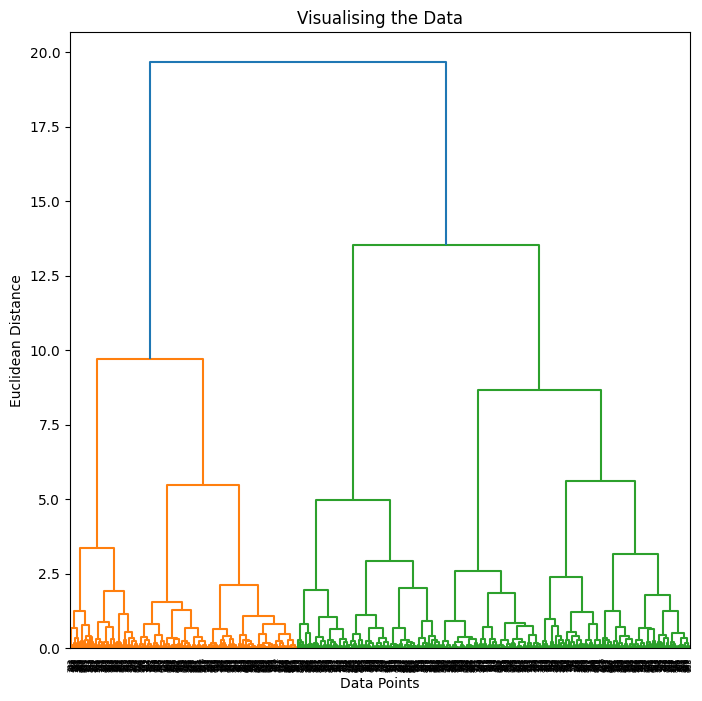

In [ ]:
# Step 6: Visualize the Dendrogram
sample_data = X_principal.sample(
    n=min(1000, len(X_principal)),
    random_state=42
)

plt.figure(figsize=(8, 8))

plt.title("Visualising the Data")

dendrogram(
    linkage(sample_data, method='ward')
)

plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")

plt.show()

In [ ]:
# Step 7: Apply Agglomerative Clustering
k = [2, 3, 4, 5, 6]

silhouette_scores = []

for i in k:

    ac = AgglomerativeClustering(n_clusters=i)
    labels = ac.fit_predict(X_principal)

    # Calculate Silhouette Score
    score = silhouette_score(
        X_principal,
        labels,
        sample_size=min(2000, len(X_principal)),
        random_state=42
    )

    silhouette_scores.append(score)

    print("Silhouette Score for K =", i, ":", score)

Silhouette Score for K = 2 : 0.44192689369657434
Silhouette Score for K = 3 : 0.42231421425014787
Silhouette Score for K = 4 : 0.3529294556187807
Silhouette Score for K = 5 : 0.354821891950481
Silhouette Score for K = 6 : 0.3256599295383986


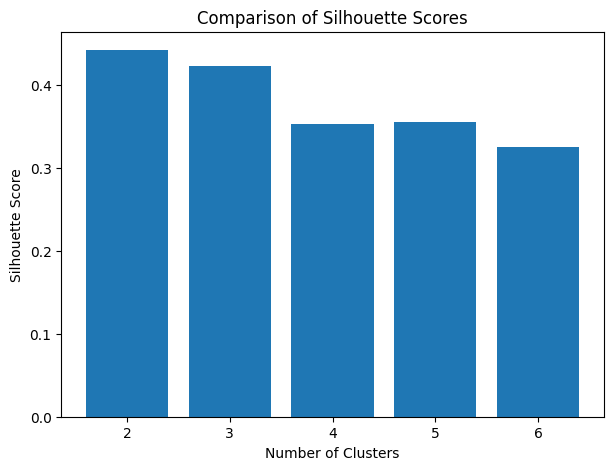

In [ ]:
# Step 8: Compare Silhouette Scores
plt.figure(figsize=(7, 5))

plt.bar(k, silhouette_scores)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.title("Comparison of Silhouette Scores")

plt.xticks(k)

plt.show()

In [ ]:
# Step 9: Find optimal number of clusters
optimal_k = k[np.argmax(silhouette_scores)]

print("\nSilhouette Scores:", silhouette_scores)

print("\nOptimal Number of Clusters:", optimal_k)

print("\nProgram completed successfully!")



Silhouette Scores: [np.float64(0.44192689369657434), np.float64(0.42231421425014787), np.float64(0.3529294556187807), np.float64(0.354821891950481), np.float64(0.3256599295383986)]

Optimal Number of Clusters: 2

Program completed successfully!
